In [1]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries are ready!")

All libraries are ready!


In [6]:
import pandas as pd

df = pd.read_csv(r"C:\Users\HP\OneDrive\Documents\Retail_Sales_EDA")

df.head()

,Order_ID,Order_Date,Product,Category,Region,Sales_Channel,Payment_Method,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Customer_Rating
0,ORD000001,2024-03-06,Bedsheet Set,Home & Kitchen,East,In-store,Debit Card,1,34.67,0.10,31.20,28.31,2.89,3.6
1,ORD000002,2025-07-19,Shampoo,Beauty,North,Mobile App,Debit Card,1,8.00,0.10,7.20,4.65,2.55,3.9
2,ORD000003,2025-04-23,Power Bank,Electronics,West,In-store,Net Banking,5,24.20,0.15,102.85,95.58,7.27,4.1
3,ORD000004,2024-11-16,Desk Lamp,Home & Kitchen,South,In-store,UPI,1,26.19,0.15,22.26,20.57,1.69,4.7
4,ORD000005,2024-11-12,Desk Lamp,Home & Kitchen,Central,Mobile App,UPI,1,26.54,0.05,25.21,20.45,4.76,3.6


In [7]:
df.shape

(15000, 14)

In [9]:
df.columns

Index(['Order_ID', 'Order_Date', 'Product', 'Category', 'Region',
       'Sales_Channel', 'Payment_Method', 'Quantity', 'Unit_Price', 'Discount',
       'Sales', 'Cost', 'Profit', 'Customer_Rating'],
      dtype='str')

In [10]:
df.info

<bound method DataFrame.info of         Order_ID  Order_Date           Product        Category   Region  \
0      ORD000001  2024-03-06      Bedsheet Set  Home & Kitchen     East   
1      ORD000002  2025-07-19           Shampoo          Beauty    North   
2      ORD000003  2025-04-23        Power Bank     Electronics     West   
3      ORD000004  2024-11-16         Desk Lamp  Home & Kitchen    South   
4      ORD000005  2024-11-12         Desk Lamp  Home & Kitchen  Central   
...          ...         ...               ...             ...      ...   
14995  ORD014996  2025-01-02  Resistance Bands          Sports    North   
14996  ORD014997  2025-01-31       Storage Box  Home & Kitchen    South   
14997  ORD014998  2025-04-28         Sunscreen          Beauty    North   
14998  ORD014999  2024-12-09           Perfume          Beauty    South   
14999  ORD015000  2024-01-18           T-Shirt        Clothing    South   

      Sales_Channel Payment_Method  Quantity  Unit_Price  Discount 

In [12]:
df.isnull().sum()

Order_ID           0
Order_Date         0
Product            0
Category           0
Region             0
Sales_Channel      0
Payment_Method     0
Quantity           0
Unit_Price         0
Discount           0
Sales              0
Cost               0
Profit             0
Customer_Rating    0
dtype: int64

In [13]:
df.duplicated().sum

<bound method Series.sum of 0        False
1        False
2        False
3        False
4        False
         ...  
14995    False
14996    False
14997    False
14998    False
14999    False
Length: 15000, dtype: bool>

In [14]:
df[["Quantity", "Unit_Price", "Discount", "Sales", "Cost", "Profit"]].describe()

,Quantity,Unit_Price,Discount,Sales,Cost,Profit
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,1.930733,28.638201,0.050160,52.527030,35.951311,16.575719
std,1.122090,16.976717,0.059899,47.334801,32.984918,17.233309
min,1.000000,4.490000,0.000000,3.780000,2.310000,-3.680000
25%,1.000000,14.830000,0.000000,20.900000,13.910000,5.610000
50%,2.000000,25.910000,0.050000,37.080000,25.280000,11.180000
75%,3.000000,37.800000,0.100000,66.265000,45.900000,20.910000
max,5.000000,78.360000,0.200000,384.800000,281.930000,166.520000


In [15]:
print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())
print("Average Customer Rating:", df["Customer_Rating"].mean())

Total Sales: 787905.45
Total Profit: 248635.78
Average Customer Rating: 3.975586666666666


In [16]:
category_sales = df.groupby("Category")[["Sales", "Profit"]].sum()

category_sales = category_sales.sort_values(
    by="Sales", ascending=False
)

category_sales

,Sales,Profit
Category,,
Clothing,240342.28,76762.72
Electronics,194420.19,60808.80
Home & Kitchen,133974.99,42007.09
Sports,92855.32,29343.13
Beauty,71137.99,22602.76
Books,55174.68,17111.28


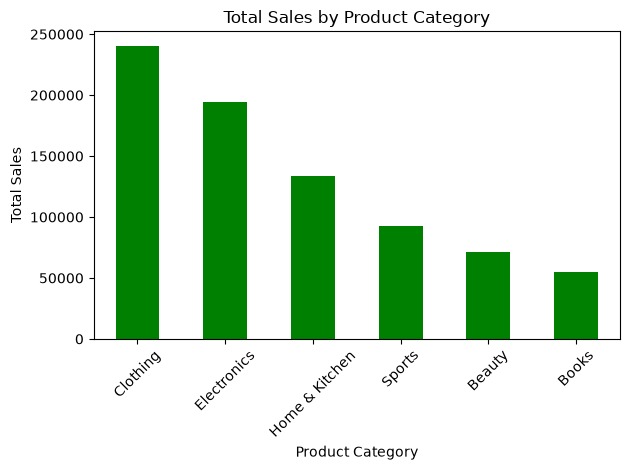

In [17]:
import matplotlib.pyplot as plt

category_sales["Sales"].plot(kind="bar", color="green")

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Month"] = df["Order_Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Sales"].sum()

monthly_sales

Month
2024-01    34868.10
2024-02    30663.88
2024-03    34259.53
2024-04    35063.82
2024-05    33234.68
2024-06    31627.18
2024-07    35199.30
2024-08    33495.70
2024-09    31027.00
2024-10    30739.71
2024-11    34162.36
2024-12    33828.61
2025-01    34353.61
2025-02    27854.36
2025-03    34702.70
2025-04    32669.24
2025-05    31793.92
2025-06    34528.13
2025-07    33639.52
2025-08    31185.88
2025-09    30262.45
2025-10    32563.13
2025-11    32187.93
2025-12    33994.71
Freq: M, Name: Sales, dtype: float64

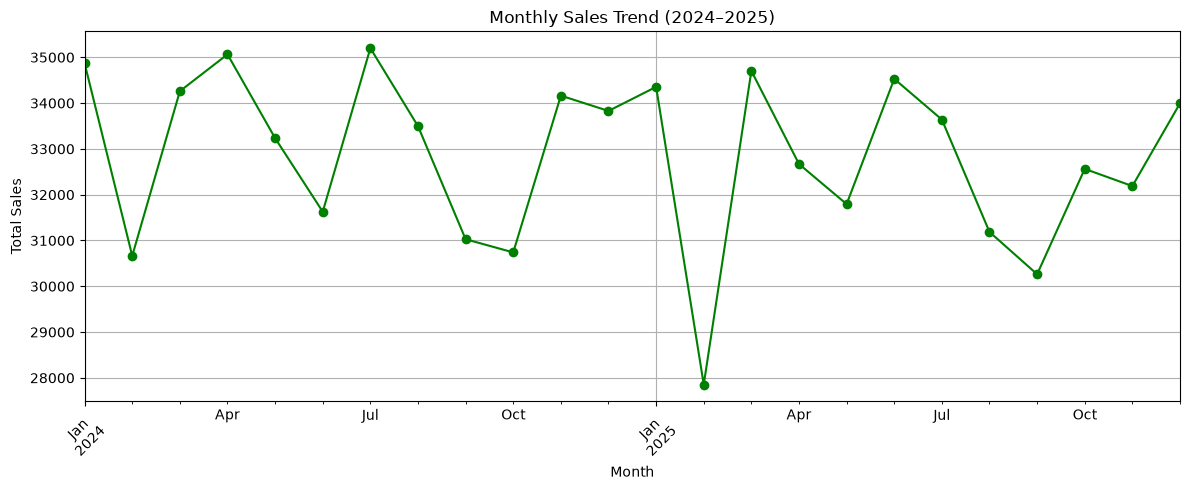

In [19]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o", color="green")

plt.title("Monthly Sales Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
highest_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()

print("Highest Sales Month:", highest_month)
print("Highest Monthly Sales:", round(monthly_sales.max(), 2))

print("Lowest Sales Month:", lowest_month)
print("Lowest Monthly Sales:", round(monthly_sales.min(), 2))

Highest Sales Month: 2024-07
Highest Monthly Sales: 35199.3
Lowest Sales Month: 2025-02
Lowest Monthly Sales: 27854.36


In [21]:
region_sales = df.groupby("Region")[["Sales", "Profit"]].sum()

region_sales = region_sales.sort_values(
    by="Sales", ascending=False
)

region_sales

,Sales,Profit
Region,,
South,191100.77,60701.42
West,180661.63,56501.42
North,169052.02,53444.71
East,124297.58,39023.35
Central,122793.45,38964.88


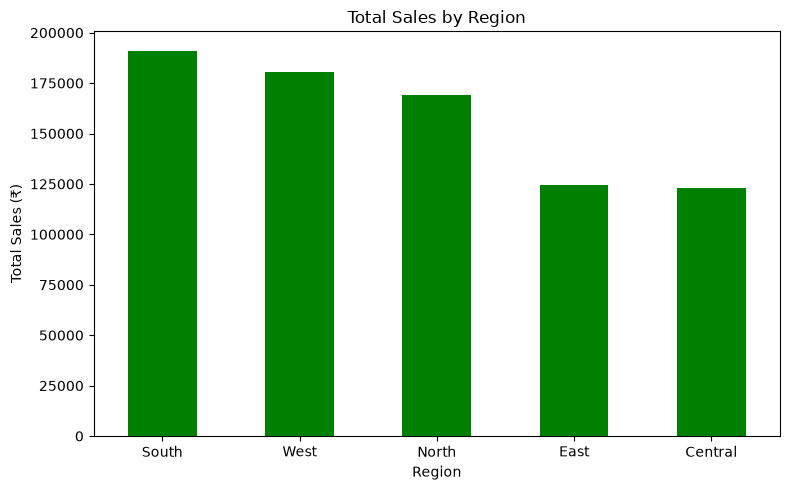

In [22]:
region_sales["Sales"].plot(
    kind="bar",
    color="green",
    figsize=(8, 5)
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
channel_sales = df.groupby("Sales_Channel")[["Sales", "Profit"]].sum()

channel_sales = channel_sales.sort_values(
    by="Sales", ascending=False
)

channel_sales

,Sales,Profit
Sales_Channel,,
Online,382961.50,121204.67
In-store,233788.98,73239.20
Mobile App,171154.97,54191.91


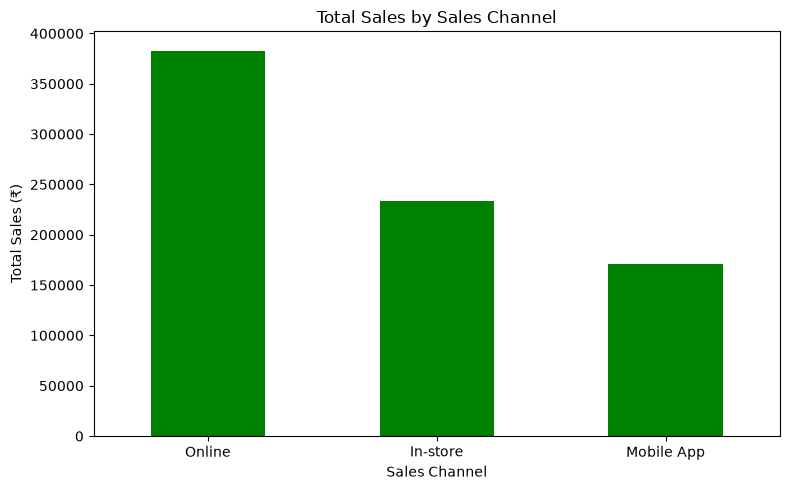

In [24]:
channel_sales["Sales"].plot(
    kind="bar",
    color="green",
    figsize=(8, 5)
)

plt.title("Total Sales by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
product_sales = df.groupby("Product")[["Sales", "Profit"]].sum()

product_sales = product_sales.sort_values(
    by="Sales", ascending=False
)

product_sales.head(10)

,Sales,Profit
Product,,
Jacket,76410.85,24631.16
Sneakers,66015.86,21012.54
Headphones,60402.96,18708.10
Cookware Set,52987.36,16578.40
Jeans,45307.03,14297.60
USB-C Hub,44917.96,14460.01
Keyboard,37209.64,11187.50
Hoodie,36331.06,11586.96
Perfume,32612.61,10543.66


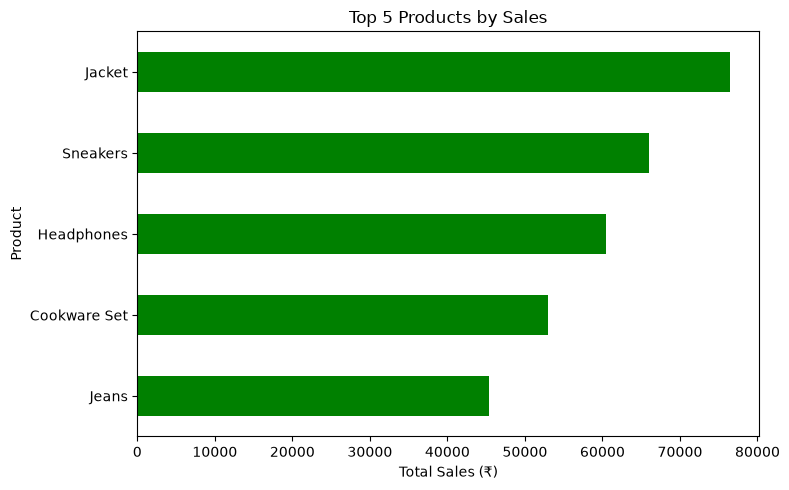

In [26]:
top_5_products = product_sales.head(5).sort_values(
    by="Sales", ascending=True
)

top_5_products["Sales"].plot(
    kind="barh",
    color="green",
    figsize=(8, 5)
)

plt.title("Top 5 Products by Sales")
plt.xlabel("Total Sales (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [27]:
category_sales["Profit_Margin_%"] = (
    category_sales["Profit"] / category_sales["Sales"]
) * 100

category_sales = category_sales.sort_values(
    by="Profit_Margin_%", ascending=False
)

category_sales.round(2)

,Sales,Profit,Profit_Margin_%
Category,,,
Clothing,240342.28,76762.72,31.94
Beauty,71137.99,22602.76,31.77
Sports,92855.32,29343.13,31.60
Home & Kitchen,133974.99,42007.09,31.35
Electronics,194420.19,60808.80,31.28
Books,55174.68,17111.28,31.01


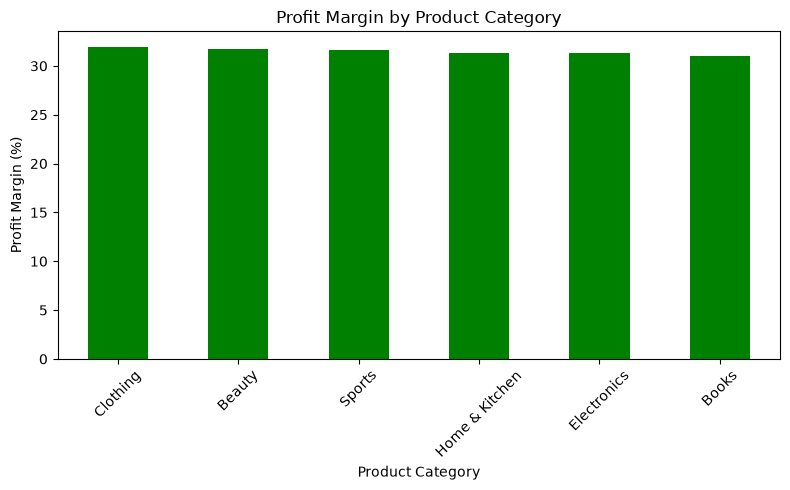

In [28]:
category_sales["Profit_Margin_%"].plot(
    kind="bar",
    color="green",
    figsize=(8, 5)
)

plt.title("Profit Margin by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
payment_sales = df.groupby("Payment_Method")[["Sales", "Profit"]].sum()

payment_sales = payment_sales.sort_values(
    by="Sales", ascending=False
)

payment_sales

,Sales,Profit
Payment_Method,,
UPI,239862.68,75435.33
Credit Card,201529.03,64040.68
Debit Card,159700.37,50215.14
Net Banking,96909.40,30231.00
Cash,89903.97,28713.63


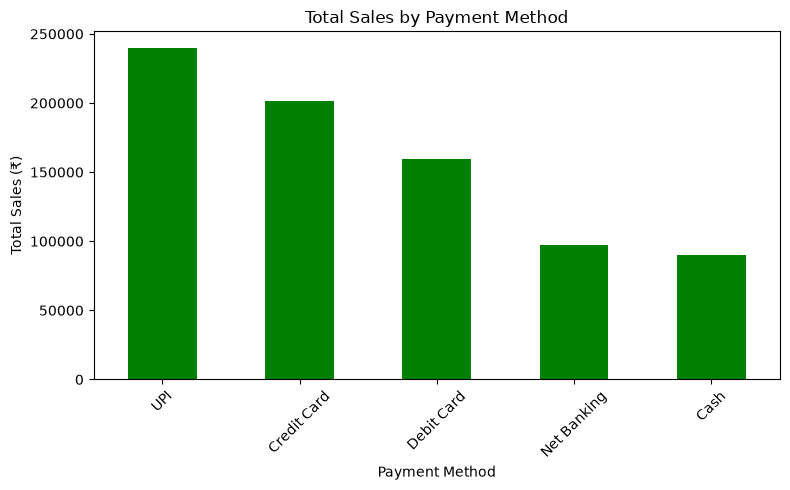

In [30]:
payment_sales["Sales"].plot(
    kind="bar",
    color="green",
    figsize=(8, 5)
)

plt.title("Total Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
product_ratings = df.groupby("Product")["Customer_Rating"].mean()

product_ratings = product_ratings.sort_values(
    ascending=False
)

product_ratings.head(10).round(2)

Product
Hoodie              4.05
Water Bottle        4.03
Face Wash           4.01
Sunscreen           4.01
Bedsheet Set        4.01
Gym Bag             4.00
Wireless Mouse      4.00
Resistance Bands    4.00
Notebook            4.00
T-Shirt             4.00
Name: Customer_Rating, dtype: float64

In [32]:
print("RETAIL SALES EDA - PROJECT SUMMARY")
print("-" * 40)

print("Total Sales: ₹", round(df["Sales"].sum(), 2))
print("Total Profit: ₹", round(df["Profit"].sum(), 2))
print("Average Customer Rating:", round(df["Customer_Rating"].mean(), 2))

print("Number of Orders:", len(df))
print("Number of Products:", df["Product"].nunique())
print("Number of Categories:", df["Category"].nunique())
print("Number of Regions:", df["Region"].nunique())

RETAIL SALES EDA - PROJECT SUMMARY
----------------------------------------
Total Sales: ₹ 787905.45
Total Profit: ₹ 248635.78
Average Customer Rating: 3.98
Number of Orders: 15000
Number of Products: 30
Number of Categories: 6
Number of Regions: 5


# Retail Sales Exploratory Data Analysis

## Project Objective
Analyze retail sales data using Python to identify sales trends, profitable categories, regional performance, and customer ratings.

## Key Findings
- Total sales: ₹787,905.45
- Total profit: ₹248,635.78
- Average customer rating: 3.98 out of 5
- Clothing generated the highest sales among categories.
- South was the leading region by sales.
- Online was the highest-selling sales channel.
- July 2024 had the highest monthly sales.

## Dataset Note
This project uses a synthetic dataset created for learning and portfolio practice. The findings do not represent actual business results.